# Notebook 1: Your First Quantum Circuit

*Quantum for Energy Academy | Lecture 5: Your First Quantum Program*  
*Prof. Lilia Tightiz, Department of Computer Engineering, Sejong University*

**Goals of this notebook**

1. Create a circuit with one qubit.
2. Inspect its ideal state, $|0\rangle$.
3. Measure the qubit in 1,024 shots and read the counts.

Run the cells from top to bottom (menu: *Run > Run All Cells*).

## 0. Check the software

The code was tested with Python 3.12 and 3.13, Qiskit 2.6.1, NumPy 2.5.4 and Matplotlib 3.11.2.

In [1]:
import sys

import matplotlib
import numpy
import qiskit

print("Python    :", sys.version.split()[0])
print("Qiskit    :", qiskit.__version__)
print("NumPy     :", numpy.__version__)
print("Matplotlib:", matplotlib.__version__)

Python    : 3.12.13
Qiskit    : 2.6.1
NumPy     : 2.5.4
Matplotlib: 3.11.2


## 1. Build a circuit with one qubit

`QuantumCircuit(1)` creates a circuit with one qubit and no gates.
Qiskit starts every qubit in the state $|0\rangle$.
The option `initial_state=True` writes this start state on the wire.

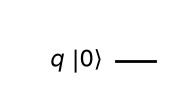

In [2]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)  # one qubit, no classical bits yet
qc.draw("mpl", initial_state=True)

## 2. Inspect the ideal state

The state $|0\rangle$ is the column vector

$$|0\rangle = \begin{bmatrix}1\\0\end{bmatrix}, \qquad P(0) = |1|^2 = 1, \qquad P(1) = |0|^2 = 0.$$

`Statevector` computes this state with exact linear algebra. No random numbers are involved.

In [3]:
from qiskit.quantum_info import Statevector

state = Statevector(qc)  # exact math, no random samples
print(state)
print("Probabilities [P(0), P(1)]:", state.probabilities())

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))
Probabilities [P(0), P(1)]: [1. 0.]


## 3. Measure the qubit

A measurement needs a place to store its result: a **classical bit**.
`QuantumCircuit(1, 1)` creates one qubit and one classical bit.
`measure(0, 0)` measures qubit 0 and writes the result into classical bit 0.

A **shot** is one complete run: prepare the qubit, apply the gates, measure once.

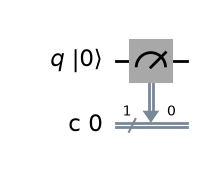

In [4]:
from qiskit.primitives import StatevectorSampler

measured = QuantumCircuit(1, 1)  # one qubit, one classical bit
measured.measure(0, 0)  # qubit 0 -> classical bit 0
measured.draw("mpl", initial_state=True)

In [5]:
sampler = StatevectorSampler(seed=42)  # local simulator, fixed seed
job = sampler.run([measured], shots=1024)
result = job.result()
counts = result[0].data.c.get_counts()
print(counts)

{'0': 1024}


The state $|0\rangle$ gives the outcome 0 with probability 1, so all 1,024 shots report `'0'`.

In [6]:
assert counts == {"0": 1024}
print("Check passed: |0> gives outcome 0 in every shot.")

Check passed: |0> gives outcome 0 in every shot.


## 4. What is inside the result?

* `result` is a `PrimitiveResult`: one entry per circuit that was submitted.
* `result[0]` is the result of the first (here, the only) circuit.
* `result[0].data.c` holds the bits of the classical register named `c`.
  The name comes from the circuit: `QuantumCircuit(1, 1)` names its classical register `c`.

In [7]:
pub_result = result[0]
bits = pub_result.data.c
print(type(result).__name__, "->", type(pub_result).__name__, "->", type(bits).__name__)
print("Shots:", bits.num_shots, "| Bits per shot:", bits.num_bits)
print("First 10 shots:", bits.get_bitstrings()[:10])

PrimitiveResult -> SamplerPubResult -> BitArray
Shots: 1024 | Bits per shot: 1
First 10 shots: ['0', '0', '0', '0', '0', '0', '0', '0', '0', '0']


## 5. Try it yourself

1. Change `shots=1024` to `shots=10`. What changes in the counts? What stays the same?
2. Add `measured.x(0)` **before** the measurement line, and run the cells again.
   Predict the counts before you run them.

Solutions: `../exercises/instructor_solutions.md`.